In [533]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pandas as pd


# Preprocessing

In [534]:
data = pd.read_csv("jakarta_house.csv")

In [535]:
data.describe()

,index,price,bed_rooms,bath_rooms,carport,land_area,building_area
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,9997.000000,9995.000000
mean,5000.50000,1.004029e+10,4.253500,3.521300,1.578900,296.610183,319.962481
std,2886.89568,2.004519e+10,3.176609,2.900136,1.743467,502.921686,357.676034
min,1.00000,1.850000e+06,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2500.75000,2.500000e+09,3.000000,2.000000,1.000000,100.000000,139.000000
50%,5000.50000,4.500000e+09,4.000000,3.000000,1.000000,177.000000,230.000000
75%,7500.25000,9.800000e+09,5.000000,4.000000,2.000000,335.000000,400.000000
max,10000.00000,9.000000e+11,63.000000,63.000000,31.000000,17714.000000,15331.000000


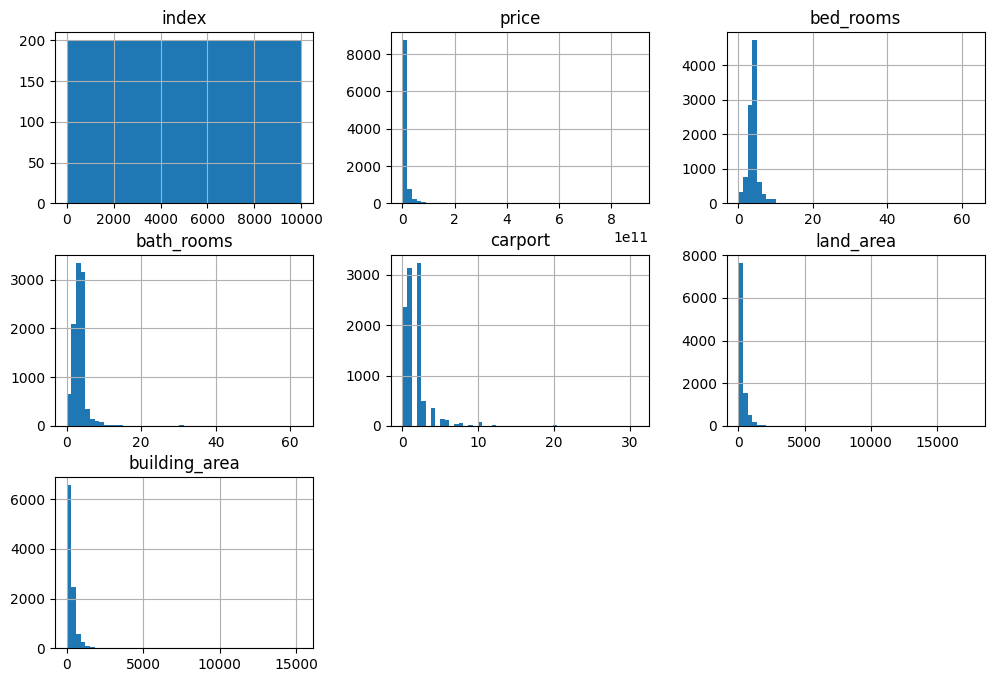

In [ ]:
data.hist(bins = 50, figsize=(12,8))
plt.title("Data Distribution Before Transformation")
plt.savefig("images/Data Distribution Before Transformation.png")
plt.show()


In [ ]:
data = data[(data.bed_rooms <= 10) & (data.carport <= 8) & (data.building_area <= 999) & (data.land_area <= 999)]

In [539]:
data.info()

<class 'pandas.DataFrame'>
Index: 9722 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          9722 non-null   int64  
 1   price          9722 non-null   int64  
 2   district       9722 non-null   str    
 3   city           9722 non-null   str    
 4   bed_rooms      9722 non-null   int64  
 5   bath_rooms     9722 non-null   int64  
 6   carport        9722 non-null   int64  
 7   land_area      9719 non-null   float64
 8   building_area  9718 non-null   float64
dtypes: float64(2), int64(5), str(2)
memory usage: 989.8 KB


In [540]:
data.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


In [541]:
data['district'].value_counts()

district
Kelapa Gading            429
Pondok Indah             383
Pantai Indah Kapuk       359
Sunter                   335
Tebet                    328
Kebayoran Baru           319
Citra Garden             255
Jagakarsa                232
Cilandak                 223
Kemang                   215
Lebak Bulus              213
Jakarta Garden City      195
Rawamangun               187
Duri Kepa                178
Jelambar                 176
Green Lake City          167
Cipete                   157
Tanjung Duren            152
Cibubur                  150
Cakung                   150
Menteng                  145
Meruya                   143
Pondok Kelapa            133
Pantai Indah Kapuk 2     132
Muara Karang             121
Duren Sawit              118
Cempaka Putih            115
Bintaro                  114
Permata Buana            111
Puri Indah               102
Kalideres                 98
Cengkareng                97
Taman Ratu                97
Pluit                     94
Metla

In [542]:
corr_matrix = data.corr(numeric_only=True)
corr_matrix['price']

index           -0.023943
price            1.000000
bed_rooms        0.239621
bath_rooms       0.290688
carport          0.271528
land_area        0.676205
building_area    0.650580
Name: price, dtype: float64

In [543]:
district_data = data['district']
district_data.value_counts()

district
Kelapa Gading            429
Pondok Indah             383
Pantai Indah Kapuk       359
Sunter                   335
Tebet                    328
Kebayoran Baru           319
Citra Garden             255
Jagakarsa                232
Cilandak                 223
Kemang                   215
Lebak Bulus              213
Jakarta Garden City      195
Rawamangun               187
Duri Kepa                178
Jelambar                 176
Green Lake City          167
Cipete                   157
Tanjung Duren            152
Cibubur                  150
Cakung                   150
Menteng                  145
Meruya                   143
Pondok Kelapa            133
Pantai Indah Kapuk 2     132
Muara Karang             121
Duren Sawit              118
Cempaka Putih            115
Bintaro                  114
Permata Buana            111
Puri Indah               102
Kalideres                 98
Cengkareng                97
Taman Ratu                97
Pluit                     94
Metla

In [544]:
counts = (data['district'].value_counts()) 
counts

district
Kelapa Gading            429
Pondok Indah             383
Pantai Indah Kapuk       359
Sunter                   335
Tebet                    328
Kebayoran Baru           319
Citra Garden             255
Jagakarsa                232
Cilandak                 223
Kemang                   215
Lebak Bulus              213
Jakarta Garden City      195
Rawamangun               187
Duri Kepa                178
Jelambar                 176
Green Lake City          167
Cipete                   157
Tanjung Duren            152
Cibubur                  150
Cakung                   150
Menteng                  145
Meruya                   143
Pondok Kelapa            133
Pantai Indah Kapuk 2     132
Muara Karang             121
Duren Sawit              118
Cempaka Putih            115
Bintaro                  114
Permata Buana            111
Puri Indah               102
Kalideres                 98
Cengkareng                97
Taman Ratu                97
Pluit                     94
Metla

In [545]:
important = counts[counts >= 100]
important

district
Kelapa Gading           429
Pondok Indah            383
Pantai Indah Kapuk      359
Sunter                  335
Tebet                   328
Kebayoran Baru          319
Citra Garden            255
Jagakarsa               232
Cilandak                223
Kemang                  215
Lebak Bulus             213
Jakarta Garden City     195
Rawamangun              187
Duri Kepa               178
Jelambar                176
Green Lake City         167
Cipete                  157
Tanjung Duren           152
Cibubur                 150
Cakung                  150
Menteng                 145
Meruya                  143
Pondok Kelapa           133
Pantai Indah Kapuk 2    132
Muara Karang            121
Duren Sawit             118
Cempaka Putih           115
Bintaro                 114
Permata Buana           111
Puri Indah              102
Name: count, dtype: int64

In [546]:
transformed_district = data['district'].where(data['district'].isin(important.index),'Others')
transformed_district.value_counts()
        

district
Others                  3685
Kelapa Gading            429
Pondok Indah             383
Pantai Indah Kapuk       359
Sunter                   335
Tebet                    328
Kebayoran Baru           319
Citra Garden             255
Jagakarsa                232
Cilandak                 223
Kemang                   215
Lebak Bulus              213
Jakarta Garden City      195
Rawamangun               187
Duri Kepa                178
Jelambar                 176
Green Lake City          167
Cipete                   157
Tanjung Duren            152
Cibubur                  150
Cakung                   150
Menteng                  145
Meruya                   143
Pondok Kelapa            133
Pantai Indah Kapuk 2     132
Muara Karang             121
Duren Sawit              118
Cempaka Putih            115
Bintaro                  114
Permata Buana            111
Puri Indah               102
Name: count, dtype: int64

In [547]:
data['district'] = transformed_district
data['district'].value_counts()

district
Others                  3685
Kelapa Gading            429
Pondok Indah             383
Pantai Indah Kapuk       359
Sunter                   335
Tebet                    328
Kebayoran Baru           319
Citra Garden             255
Jagakarsa                232
Cilandak                 223
Kemang                   215
Lebak Bulus              213
Jakarta Garden City      195
Rawamangun               187
Duri Kepa                178
Jelambar                 176
Green Lake City          167
Cipete                   157
Tanjung Duren            152
Cibubur                  150
Cakung                   150
Menteng                  145
Meruya                   143
Pondok Kelapa            133
Pantai Indah Kapuk 2     132
Muara Karang             121
Duren Sawit              118
Cempaka Putih            115
Bintaro                  114
Permata Buana            111
Puri Indah               102
Name: count, dtype: int64

In [548]:
transformed_district_index = pd.Series(important.index)
transformed_district_index.to_csv('Important_Districts.csv')

In [549]:
data.info()

<class 'pandas.DataFrame'>
Index: 9722 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          9722 non-null   int64  
 1   price          9722 non-null   int64  
 2   district       9722 non-null   str    
 3   city           9722 non-null   str    
 4   bed_rooms      9722 non-null   int64  
 5   bath_rooms     9722 non-null   int64  
 6   carport        9722 non-null   int64  
 7   land_area      9719 non-null   float64
 8   building_area  9718 non-null   float64
dtypes: float64(2), int64(5), str(2)
memory usage: 975.5 KB


In [550]:
data['city'].value_counts()

city
Jakarta Selatan    3232
Jakarta Barat      2566
Jakarta Utara      1715
Jakarta Timur      1673
Jakarta Pusat       536
Name: count, dtype: int64

In [551]:
data.describe()

,index,price,bed_rooms,bath_rooms,carport,land_area,building_area
count,9722.000000,9.722000e+03,9722.000000,9722.000000,9722.000000,9719.000000,9718.000000
mean,4995.901461,9.333414e+09,3.929747,3.275561,1.455565,276.537092,305.810455
std,2888.987639,1.593470e+10,1.511572,1.435253,1.306032,370.075822,289.477082
min,1.000000,1.850000e+06,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2492.250000,2.450000e+09,3.000000,2.000000,1.000000,100.000000,135.000000
50%,4992.500000,4.300000e+09,4.000000,3.000000,1.000000,170.000000,220.000000
75%,7499.750000,9.300000e+09,5.000000,4.000000,2.000000,322.000000,385.000000
max,10000.000000,3.700000e+11,10.000000,13.000000,8.000000,17714.000000,6800.000000


In [553]:
X = data.drop(columns=['price'])
y = data['price']

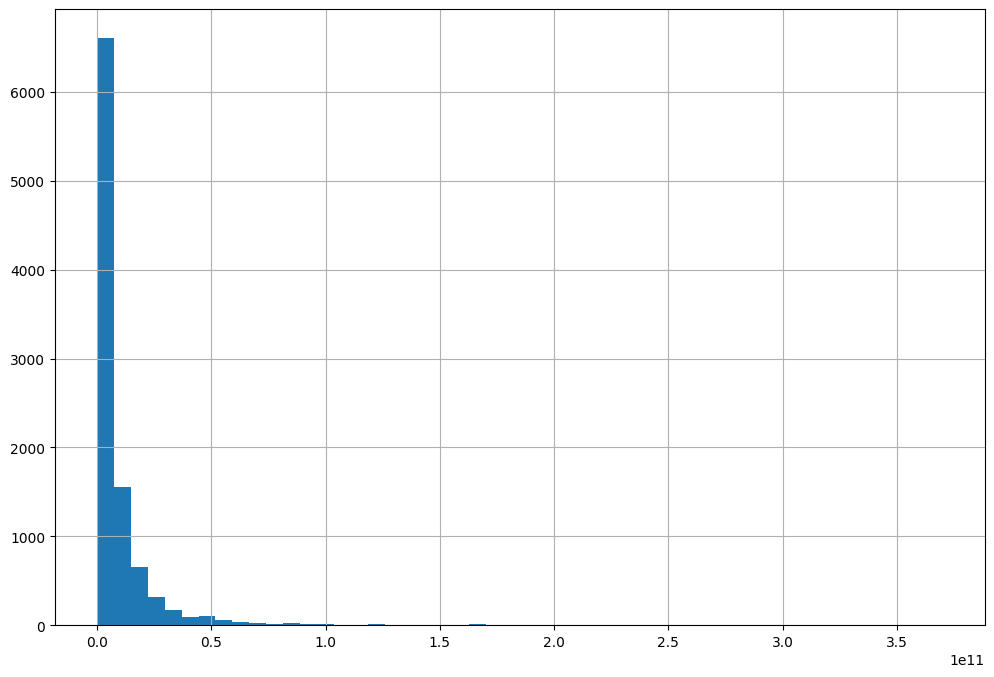

In [554]:
y.hist(figsize=(12,8),bins=50)
plt.show()

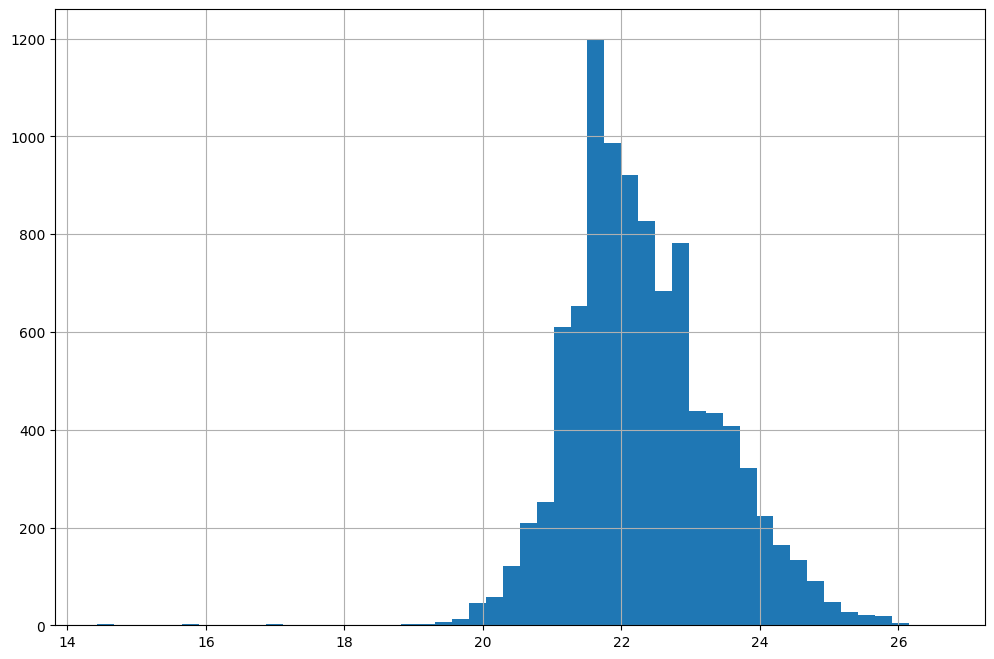

In [ ]:
np.log1p(y).hist(figsize = (12,8), bins = 50)
plt.title("Log Transformed Price")
plt.savefig("images/Log Transformed Price.png")
plt.show()


In [556]:
X.info()

<class 'pandas.DataFrame'>
Index: 9722 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          9722 non-null   int64  
 1   district       9722 non-null   str    
 2   city           9722 non-null   str    
 3   bed_rooms      9722 non-null   int64  
 4   bath_rooms     9722 non-null   int64  
 5   carport        9722 non-null   int64  
 6   land_area      9719 non-null   float64
 7   building_area  9718 non-null   float64
dtypes: float64(2), int64(4), str(2)
memory usage: 899.6 KB


In [557]:
y.info()

<class 'pandas.Series'>
Index: 9722 entries, 0 to 9999
Series name: price
Non-Null Count  Dtype
--------------  -----
9722 non-null   int64
dtypes: int64(1)
memory usage: 151.9 KB


In [558]:
y = np.log1p(y)

# Data Splitting

In [559]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.3,stratify=X['district'],random_state=67
    
)

In [560]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 6805 entries, 6675 to 5936
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          6805 non-null   int64  
 1   district       6805 non-null   str    
 2   city           6805 non-null   str    
 3   bed_rooms      6805 non-null   int64  
 4   bath_rooms     6805 non-null   int64  
 5   carport        6805 non-null   int64  
 6   land_area      6804 non-null   float64
 7   building_area  6803 non-null   float64
dtypes: float64(2), int64(4), str(2)
memory usage: 630.5 KB


In [561]:
X_train.describe()

,index,bed_rooms,bath_rooms,carport,land_area,building_area
count,6805.000000,6805.000000,6805.000000,6805.000000,6804.000000,6803.000000
mean,4973.328729,3.914769,3.267303,1.456576,276.989418,305.847420
std,2886.390480,1.506822,1.437753,1.308769,397.658663,298.274032
min,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2449.000000,3.000000,2.000000,1.000000,100.000000,132.000000
50%,4987.000000,4.000000,3.000000,1.000000,170.000000,220.000000
75%,7463.000000,5.000000,4.000000,2.000000,318.000000,380.000000
max,9999.000000,10.000000,13.000000,8.000000,17714.000000,6800.000000


In [562]:
X_test.info()

<class 'pandas.DataFrame'>
Index: 2917 entries, 3141 to 3003
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          2917 non-null   int64  
 1   district       2917 non-null   str    
 2   city           2917 non-null   str    
 3   bed_rooms      2917 non-null   int64  
 4   bath_rooms     2917 non-null   int64  
 5   carport        2917 non-null   int64  
 6   land_area      2915 non-null   float64
 7   building_area  2915 non-null   float64
dtypes: float64(2), int64(4), str(2)
memory usage: 270.3 KB


# Scikit-Learn Pipeline 

In [563]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.preprocessing import PolynomialFeatures, FunctionTransformer
cat_features = ['district','city']
num_features = ['bed_rooms','bath_rooms','carport']
num_log_features = ['land_area','building_area']
num_pipeline = Pipeline([
    ("impute",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
    
])

num_log_pipeline = Pipeline([
      ("impute",SimpleImputer(strategy="median")),
      ("log",FunctionTransformer(func=np.log1p,feature_names_out="one-to-one")),
      ("scaler",StandardScaler())
])


quadratic_pipeline = Pipeline([
    ("impute",SimpleImputer(strategy="median")),
    ("quadratic", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler",StandardScaler())

])

quadratic_log_pipeline = Pipeline([
      ("impute",SimpleImputer(strategy="median")),
      ("log",FunctionTransformer(func=np.log1p,feature_names_out="one-to-one")),
      ("quadratic", PolynomialFeatures(degree=2, include_bias=False)),
      ("scaler",StandardScaler())
])

cat_pipeline = Pipeline([
    ("encoder",OneHotEncoder(drop='first',sparse_output=False,handle_unknown='ignore'))
])

preprocessing = ColumnTransformer([
    ("num",num_pipeline,num_features),
    ("log",num_log_pipeline,num_log_features),
    ("cat",cat_pipeline,cat_features)
])



preprocessing_quad = ColumnTransformer([
    ("quad",quadratic_pipeline,num_features),
    ("log",quadratic_log_pipeline,num_log_features),
    ("cat",cat_pipeline,cat_features)
])

In [564]:
X_train_transformed = preprocessing.fit_transform(X_train)

In [565]:
X_train_transformed = pd.DataFrame(X_train_transformed,columns= preprocessing.get_feature_names_out(),index = X_train.index)

In [566]:
X_train_transformed.info()

<class 'pandas.DataFrame'>
Index: 6805 entries, 6675 to 5936
Data columns (total 39 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   num__bed_rooms                      6805 non-null   float64
 1   num__bath_rooms                     6805 non-null   float64
 2   num__carport                        6805 non-null   float64
 3   log__land_area                      6805 non-null   float64
 4   log__building_area                  6805 non-null   float64
 5   cat__district_Cakung                6805 non-null   float64
 6   cat__district_Cempaka Putih         6805 non-null   float64
 7   cat__district_Cibubur               6805 non-null   float64
 8   cat__district_Cilandak              6805 non-null   float64
 9   cat__district_Cipete                6805 non-null   float64
 10  cat__district_Citra Garden          6805 non-null   float64
 11  cat__district_Duren Sawit           6805 non-null   floa

In [567]:
X_train_transformed.describe()

,num__bed_rooms,num__bath_rooms,num__carport,log__land_area,log__building_area,cat__district_Cakung,cat__district_Cempaka Putih,cat__district_Cibubur,cat__district_Cilandak,cat__district_Cipete,cat__district_Citra Garden,cat__district_Duren Sawit,cat__district_Duri Kepa,cat__district_Green Lake City,cat__district_Jagakarsa,cat__district_Jakarta Garden City,cat__district_Jelambar,cat__district_Kebayoran Baru,cat__district_Kelapa Gading,cat__district_Kemang,cat__district_Lebak Bulus,cat__district_Menteng,cat__district_Meruya,cat__district_Muara Karang,cat__district_Others,cat__district_Pantai Indah Kapuk,cat__district_Pantai Indah Kapuk 2,cat__district_Permata Buana,cat__district_Pondok Indah,cat__district_Pondok Kelapa,cat__district_Puri Indah,cat__district_Rawamangun,cat__district_Sunter,cat__district_Tanjung Duren,cat__district_Tebet,cat__city_Jakarta Pusat,cat__city_Jakarta Selatan,cat__city_Jakarta Timur,cat__city_Jakarta Utara
count,6.805000e+03,6.805000e+03,6.805000e+03,6.805000e+03,6.805000e+03,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.00000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000,6805.000000
mean,-8.770843e-17,-1.420041e-16,7.935525e-17,-1.252978e-16,-8.932686e-16,0.015430,0.011903,0.015430,0.022924,0.016165,0.026157,0.012197,0.018369,0.017193,0.023806,0.020132,0.018075,0.032770,0.044085,0.02219,0.021896,0.014989,0.014695,0.012491,0.378986,0.036885,0.013519,0.011462,0.039383,0.013666,0.010434,0.019251,0.034386,0.015577,0.033799,0.055253,0.332109,0.173108,0.176047
std,1.000073e+00,1.000073e+00,1.000073e+00,1.000073e+00,1.000073e+00,0.123264,0.108458,0.123264,0.149673,0.126118,0.159614,0.109772,0.134291,0.130000,0.152456,0.140463,0.133232,0.178047,0.205300,0.14731,0.146354,0.121517,0.120338,0.111070,0.485170,0.188492,0.115493,0.106454,0.194518,0.116110,0.101618,0.137414,0.182233,0.123840,0.180724,0.228491,0.471004,0.378368,0.380888
min,-2.598221e+00,-2.272674e+00,-1.113017e+00,-5.388160e+00,-5.642674e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-6.071293e-01,-8.815121e-01,-3.488847e-01,-7.308846e-01,-6.181307e-01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5.656787e-02,-1.859312e-01,-3.488847e-01,-1.056240e-01,-1.021822e-02,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,7.202651e-01,5.096497e-01,4.152480e-01,6.348041e-01,6.417758e-01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
max,4.038751e+00,6.769878e+00,5.000044e+00,5.404893e+00,4.091899e+00,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0

In [568]:
X_train_transformed.head()

,num__bed_rooms,num__bath_rooms,num__carport,log__land_area,log__building_area,cat__district_Cakung,cat__district_Cempaka Putih,cat__district_Cibubur,cat__district_Cilandak,cat__district_Cipete,cat__district_Citra Garden,cat__district_Duren Sawit,cat__district_Duri Kepa,cat__district_Green Lake City,cat__district_Jagakarsa,cat__district_Jakarta Garden City,cat__district_Jelambar,cat__district_Kebayoran Baru,cat__district_Kelapa Gading,cat__district_Kemang,cat__district_Lebak Bulus,cat__district_Menteng,cat__district_Meruya,cat__district_Muara Karang,cat__district_Others,cat__district_Pantai Indah Kapuk,cat__district_Pantai Indah Kapuk 2,cat__district_Permata Buana,cat__district_Pondok Indah,cat__district_Pondok Kelapa,cat__district_Puri Indah,cat__district_Rawamangun,cat__district_Sunter,cat__district_Tanjung Duren,cat__district_Tebet,cat__city_Jakarta Pusat,cat__city_Jakarta Selatan,cat__city_Jakarta Timur,cat__city_Jakarta Utara
6675,0.056568,-0.881512,0.415248,-0.854693,-0.947612,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1868,-2.598221,0.509650,-1.113017,1.279497,1.187417,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4796,1.383962,0.509650,-1.113017,1.919366,0.969555,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
6869,0.056568,-0.185931,-0.348885,-0.031593,0.436640,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3404,-1.270827,-0.881512,-1.113017,-2.540701,-2.026871,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


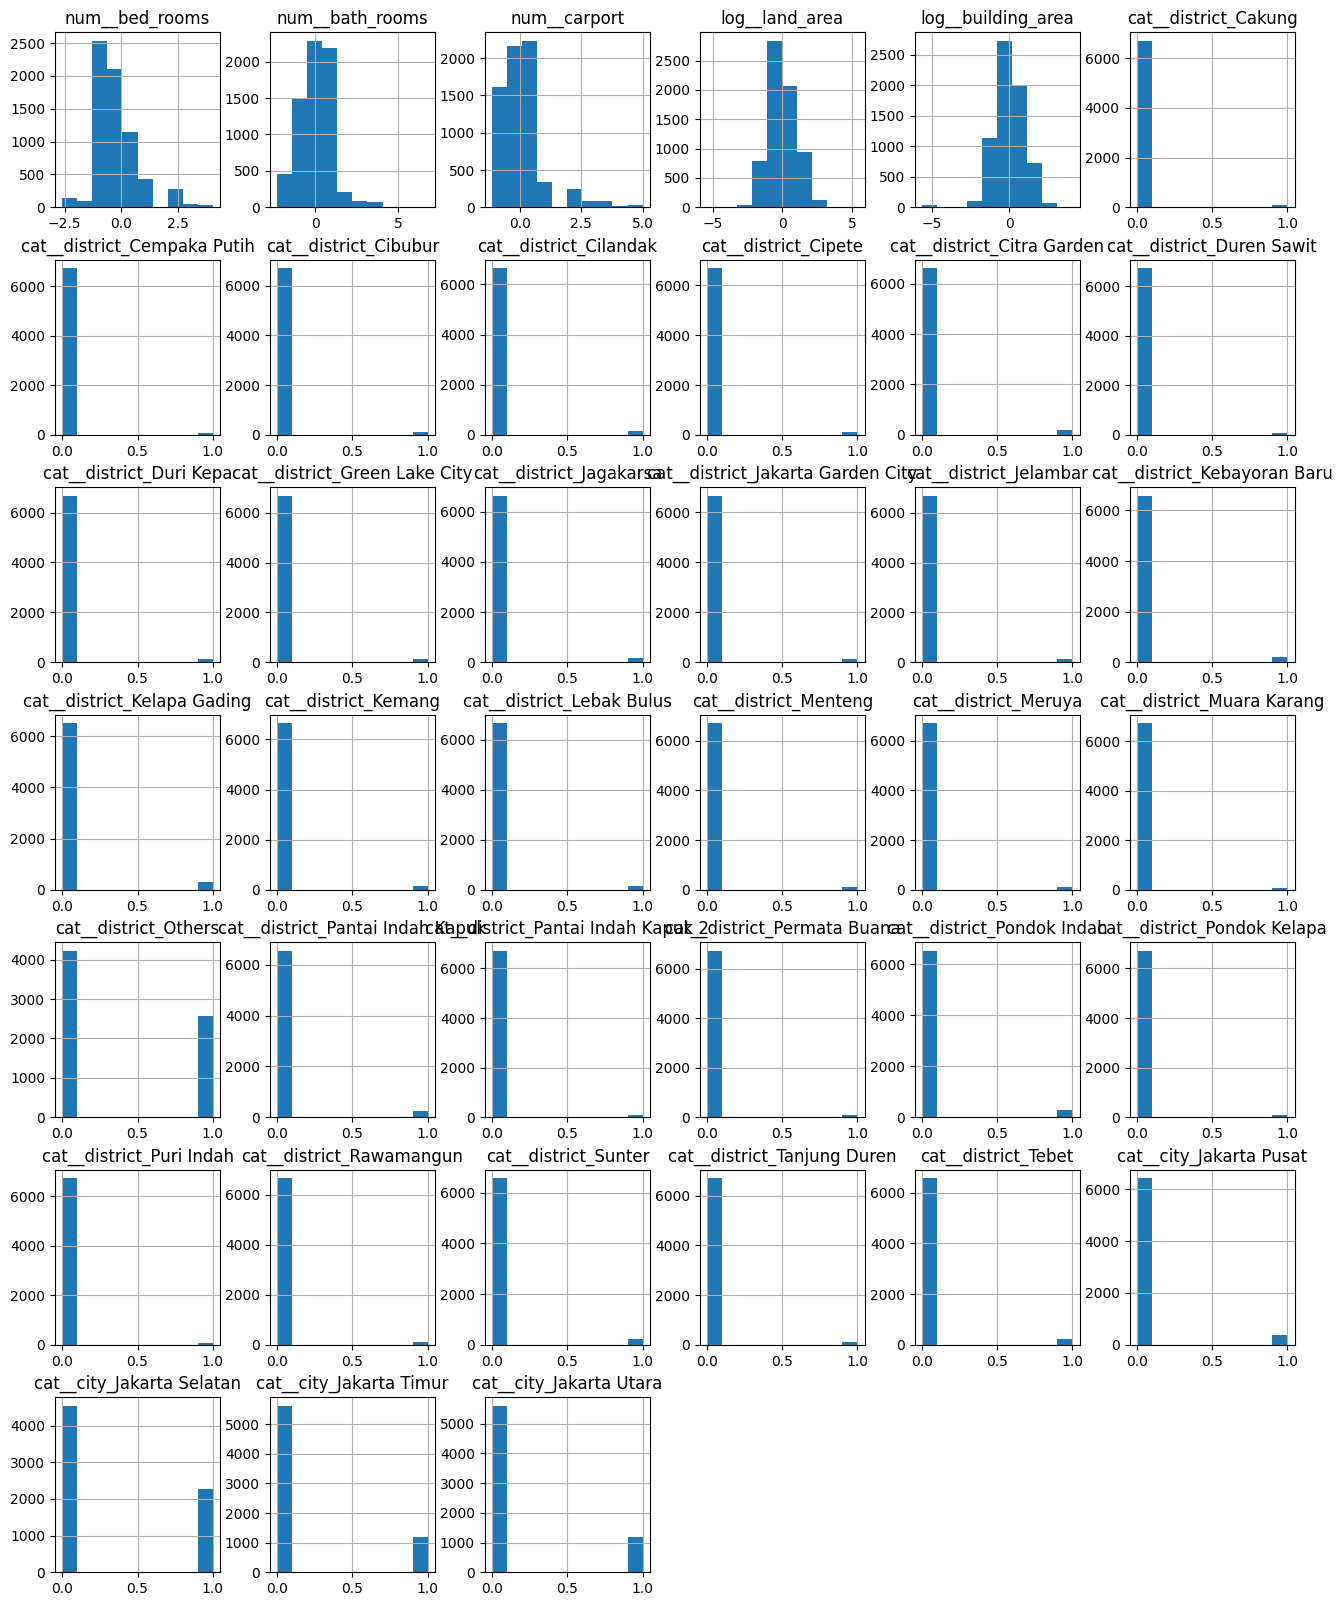

In [ ]:
X_train_transformed[:5].hist(figsize=(18,20))
plt.title("Features Distribution After Transformation")
plt.savefig("images/Features Distribution After Transformation.png")
plt.show()


In [570]:
X_test_transformed = preprocessing.fit_transform(X_test)

In [571]:
X_test_transformed = pd.DataFrame(X_test_transformed,columns=preprocessing.get_feature_names_out(),index=X_test.index)

# Model Fitting

In [572]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

linreg_model = Pipeline([
    ("preprocess",preprocessing),
    ("model",LinearRegression())
])
cv_rmses = -cross_val_score(linreg_model, X_train, y_train,scoring="neg_root_mean_squared_error",cv = 5)
cv_rmses = pd.Series(cv_rmses)
linear_cvs_desc = cv_rmses.describe()
linear_cvs_desc.to_csv("Linear CV description.csv")

In [573]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_squared_error, r2_score


linreg_model.fit(X_train,y_train)
prediction = linreg_model.predict(X_test)
lin_rmse = root_mean_squared_error(y_test,prediction)
lin_mse = mean_squared_error(y_test,prediction)
lin_mae = mean_absolute_error(y_test,prediction)
lin_r2 = r2_score(y_test,prediction)

print(f"RMSE: {lin_rmse}")
print(f"MSE: {lin_mse}")
print(f"MAE: {lin_mae}")
print(f"R2: {lin_r2}")
print(f"Coefficients: {linreg_model["model"].coef_}")
print(f"Intercept: {linreg_model["model"].intercept_}")

linreg_results = pd.Series([lin_rmse, lin_mse,lin_mae, lin_r2], index=["RMSE","MSE","MAE","R2"])
linreg_results.to_csv("LinReg Prediction Results.csv")


RMSE: 0.4543493461882271
MSE: 0.20643332838166945
MAE: 0.28101401342251436
R2: 0.8204137324102362
Coefficients: [-0.03730051  0.10238007  0.02328675  0.61486095  0.20257604  0.34246901
  0.24604615  0.04573251  0.27725142  0.37784279  0.25284215  0.30747021
  0.35106889  0.37281452 -0.04010028  0.40379612  0.34049602  1.11781524
  0.32272029  0.4044866   0.19770255  1.20489891  0.16781427  0.42316447
  0.30481289  0.72568777  0.39418136  0.73088456  0.82912328  0.13935451
  0.59852706  0.57955422  0.40855125  0.50483057  0.3500246   0.17221772
  0.13007089 -0.2734867   0.12867748]
Intercept: 21.8956280053695


In [574]:
coefs = pd.Series(linreg_model["model"].coef_, index = preprocessing.get_feature_names_out()).sort_values(ascending=False)
coefs[:5].to_csv("Five Highest Coefficients Lin Reg.csv")
coefs.to_csv("LinReg Coefs.csv")

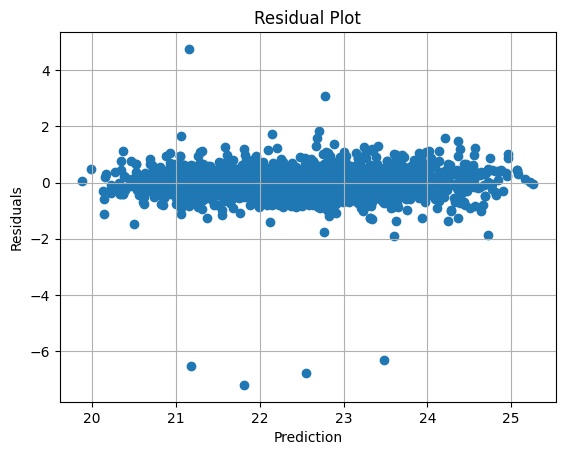

In [ ]:
plt.scatter(prediction, (y_test - prediction))
plt.title("Linear Regression Residual Plot")
plt.grid(True)
plt.xlabel("Prediction")
plt.ylabel("Residuals")
plt.show()
plt.savefig("images/Linear Regression Residual PLot.png")

In [577]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF
X_train_intercept = sm.add_constant(X_train_transformed)
sm_linreg = sm.OLS(y_train,X_train_intercept).fit()
sm_linreg.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.822
Model:                            OLS   Adj. R-squared:                  0.821
Method:                 Least Squares   F-statistic:                     802.4
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        00:00:13   Log-Likelihood:                -4221.7
No. Observations:                6805   AIC:                             8523.
Df Residuals:                    6765   BIC:                             8797.
Df Model:                          39                                         
Covariance Type:            nonrobust                                         
======================================================================================================
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
const                                 21.8956      0.055    396.024      0.000      21.787      22.004
num__bed_rooms                        -0.0373      0.008     -4.577      0.000      -0.053      -0.021
num__bath_rooms                        0.1024      0.008     12.276      0.000       0.086       0.119
num__carport                           0.0233      0.006      3.813      0.000       0.011       0.035
log__land_area                         0.6149      0.009     68.304      0.000       0.597       0.633
log__building_area                     0.2026      0.009     22.397      0.000       0.185       0.220
cat__district_Cakung                   0.3425      0.072      4.768      0.000       0.202       0.483
cat__district_Cempaka Putih            0.2460      0.080      3.076      0.002       0.089       0.403
cat__district_Cibubur                  0.0457      0.072      0.637      0.524      -0.095       0.187
cat__district_Cilandak                 0.2773      0.062      4.464      0.000       0.155       0.399
cat__district_Cipete                   0.3778      0.066      5.690      0.000       0.248       0.508
cat__district_Citra Garden             0.2528      0.065      3.901      0.000       0.126       0.380
cat__district_Duren Sawit              0.3075      0.075      4.079      0.000       0.160       0.455
cat__district_Duri Kepa                0.3511      0.069      5.123      0.000       0.217       0.485
cat__district_Green Lake City          0.3728      0.069      5.376      0.000       0.237       0.509
cat__district_Jagakarsa               -0.0401      0.062     -0.647      0.518      -0.162       0.081
cat__district_Jakarta Garden City      0.4038      0.069      5.886      0.000       0.269       0.538
cat__district_Jelambar                 0.3405      0.069      4.953      0.000       0.206       0.475
cat__district_Kebayoran Baru           1.1178      0.059     18.951      0.000       1.002       1.233
cat__district_Kelapa Gading            0.3227      0.066      4.879      0.000       0.193       0.452
cat__district_Kemang                   0.4045      0.063      6.449      0.000       0.282       0.527
cat__district_Lebak Bulus              0.1977      0.063      3.158      0.002       0.075       0.320
cat__district_Menteng                  1.2049      0.077     15.558      0.000       1.053       1.357
cat__district_Meruya                   0.1678      0.071      2.352      0.019       0.028       0.308
cat__district_Muara Karang             0.4232      0.078      5.423      0.000       0.270       0.576
cat__district_Others                   0.3048      0.053      5.733      0.000       0.201       0.409
cat__district_Pantai Indah Kapuk       0.7257      0.067     10.798      0.000       0.594      

In [578]:
vif_linear = [VIF(X_train_intercept,i) for i in range(1,X_train_intercept.shape[1])]
vif_linear = pd.Series(vif_linear,index=X_train_intercept.columns[1:])
vif_linear_sus = vif_linear[vif_linear >= 5]
vif_linear_sus.to_csv("High VIF Linear Model.csv")

In [579]:
X_train_transformed_quad = preprocessing_quad.fit_transform(X_train)
X_test_transformed_quad = preprocessing_quad.fit_transform(X_test)

In [580]:
X_train_transformed_quad = pd.DataFrame(X_train_transformed_quad,columns=preprocessing_quad.get_feature_names_out(),index=X_train.index)
X_test_transformed_quad = pd.DataFrame(X_test_transformed_quad,columns=preprocessing_quad.get_feature_names_out(),index=X_test.index)


In [581]:
X_train_transformed_quad.info()

<class 'pandas.DataFrame'>
Index: 6805 entries, 6675 to 5936
Data columns (total 48 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   quad__bed_rooms                     6805 non-null   float64
 1   quad__bath_rooms                    6805 non-null   float64
 2   quad__carport                       6805 non-null   float64
 3   quad__bed_rooms^2                   6805 non-null   float64
 4   quad__bed_rooms bath_rooms          6805 non-null   float64
 5   quad__bed_rooms carport             6805 non-null   float64
 6   quad__bath_rooms^2                  6805 non-null   float64
 7   quad__bath_rooms carport            6805 non-null   float64
 8   quad__carport^2                     6805 non-null   float64
 9   log__land_area                      6805 non-null   float64
 10  log__building_area                  6805 non-null   float64
 11  log__land_area^2                    6805 non-null   floa

In [582]:
quad_reg_cv = -cross_val_score(LinearRegression(), X_train_transformed_quad, y_train,scoring="neg_root_mean_squared_error",cv=5)
quad_reg_cv = pd.Series(quad_reg_cv)
quad_reg_cv.describe()

count    5.000000
mean     0.432113
std      0.062753
min      0.349813
25%      0.410635
50%      0.435732
75%      0.440428
max      0.523955
dtype: float64

In [583]:
quad_reg = LinearRegression()
quad_reg.fit(X_train_transformed_quad, y_train)
prediction_quad = quad_reg.predict(X_test_transformed_quad)

print(f"RMSE: {root_mean_squared_error(y_test,prediction_quad)}")
print(f"MSE: {mean_squared_error(y_test,prediction_quad)}")
print(f"MAE: {mean_absolute_error(y_test,prediction_quad)}")
print(f"R2: {r2_score(y_test,prediction_quad)}")

RMSE: 0.4416879573298632
MSE: 0.19508825165022706
MAE: 0.2727155964239825
R2: 0.8302833595760215


In [584]:
price_in_rupiah = pd.Series(np.expm1(prediction_quad))
price_in_rupiah.describe()

count    2.917000e+03
mean     8.255764e+09
std      1.066747e+10
min      4.286761e+08
25%      2.386754e+09
50%      4.368277e+09
75%      9.510960e+09
max      1.093037e+11
dtype: float64

In [585]:
X_train_transformed_quad_with_intercept = sm.add_constant(X_train_transformed_quad)
sm_model_quad = sm.OLS(y_train,X_train_transformed_quad_with_intercept).fit()

In [586]:
sm_model_quad.params

const                                 21.917845
quad__bed_rooms                       -0.049701
quad__bath_rooms                       0.139286
quad__carport                          0.068987
quad__bed_rooms^2                      0.019548
quad__bed_rooms bath_rooms            -0.029050
quad__bed_rooms carport               -0.002887
quad__bath_rooms^2                    -0.043723
quad__bath_rooms carport              -0.044390
quad__carport^2                       -0.007658
log__land_area                         0.467292
log__building_area                     0.256819
log__land_area^2                       0.847711
log__land_area building_area          -1.480085
log__building_area^2                   0.847734
cat__district_Cakung                   0.365483
cat__district_Cempaka Putih            0.230989
cat__district_Cibubur                  0.038269
cat__district_Cilandak                 0.254782
cat__district_Cipete                   0.369904
cat__district_Citra Garden             0

In [587]:
print(sm_model_quad.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.836
Model:                            OLS   Adj. R-squared:                  0.835
Method:                 Least Squares   F-statistic:                     719.2
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        00:00:16   Log-Likelihood:                -3940.7
No. Observations:                6805   AIC:                             7979.
Df Residuals:                    6756   BIC:                             8314.
Df Model:                          48                                         
Covariance Type:            nonrobust                                         
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
cons

In [588]:
X_train_transformed_quad_with_intercept_num_only = X_train_transformed_quad_with_intercept.drop(X_train_transformed_quad_with_intercept.columns[21:],axis =1)
X_train_transformed_quad_with_intercept_cat_only = X_train_transformed_quad_with_intercept.drop(X_train_transformed_quad_with_intercept.columns[:21], axis =1)

In [589]:
print(X_train_transformed_quad_with_intercept_cat_only.columns)

Index(['cat__district_Duren Sawit', 'cat__district_Duri Kepa',
       'cat__district_Green Lake City', 'cat__district_Jagakarsa',
       'cat__district_Jakarta Garden City', 'cat__district_Jelambar',
       'cat__district_Kebayoran Baru', 'cat__district_Kelapa Gading',
       'cat__district_Kemang', 'cat__district_Lebak Bulus',
       'cat__district_Menteng', 'cat__district_Meruya',
       'cat__district_Muara Karang', 'cat__district_Others',
       'cat__district_Pantai Indah Kapuk',
       'cat__district_Pantai Indah Kapuk 2', 'cat__district_Permata Buana',
       'cat__district_Pondok Indah', 'cat__district_Pondok Kelapa',
       'cat__district_Puri Indah', 'cat__district_Rawamangun',
       'cat__district_Sunter', 'cat__district_Tanjung Duren',
       'cat__district_Tebet', 'cat__city_Jakarta Pusat',
       'cat__city_Jakarta Selatan', 'cat__city_Jakarta Timur',
       'cat__city_Jakarta Utara'],
      dtype='str')


In [590]:
X_train_transformed_quad_with_intercept_num_only.info()

<class 'pandas.DataFrame'>
Index: 6805 entries, 6675 to 5936
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   const                         6805 non-null   float64
 1   quad__bed_rooms               6805 non-null   float64
 2   quad__bath_rooms              6805 non-null   float64
 3   quad__carport                 6805 non-null   float64
 4   quad__bed_rooms^2             6805 non-null   float64
 5   quad__bed_rooms bath_rooms    6805 non-null   float64
 6   quad__bed_rooms carport       6805 non-null   float64
 7   quad__bath_rooms^2            6805 non-null   float64
 8   quad__bath_rooms carport      6805 non-null   float64
 9   quad__carport^2               6805 non-null   float64
 10  log__land_area                6805 non-null   float64
 11  log__building_area            6805 non-null   float64
 12  log__land_area^2              6805 non-null   float64
 13  log__land_area b

In [591]:

X_train_transformed_quad_with_intercept_cat_only = sm.add_constant(X_train_transformed_quad_with_intercept_cat_only)
X_train_transformed_quad_with_intercept_cat_only.info()

<class 'pandas.DataFrame'>
Index: 6805 entries, 6675 to 5936
Data columns (total 29 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   const                               6805 non-null   float64
 1   cat__district_Duren Sawit           6805 non-null   float64
 2   cat__district_Duri Kepa             6805 non-null   float64
 3   cat__district_Green Lake City       6805 non-null   float64
 4   cat__district_Jagakarsa             6805 non-null   float64
 5   cat__district_Jakarta Garden City   6805 non-null   float64
 6   cat__district_Jelambar              6805 non-null   float64
 7   cat__district_Kebayoran Baru        6805 non-null   float64
 8   cat__district_Kelapa Gading         6805 non-null   float64
 9   cat__district_Kemang                6805 non-null   float64
 10  cat__district_Lebak Bulus           6805 non-null   float64
 11  cat__district_Menteng               6805 non-null   floa

In [592]:
sm_model_num_only = sm.OLS(y_train,X_train_transformed_quad_with_intercept_num_only).fit()
sm_model_cat_only = sm.OLS(y_train,X_train_transformed_quad_with_intercept_cat_only).fit()


In [593]:
anova_results_num = sm.stats.anova_lm(sm_model_num_only,sm_model_quad)
anova_results_cat = sm.stats.anova_lm(sm_model_cat_only,sm_model_quad)


In [594]:
anova_results_num

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,6784.0,1710.738629,0.0,NaN,NaN,NaN
1,6756.0,1268.648311,28.0,442.090318,84.081677,0.0


In [595]:
anova_results_cat

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,6776.0,4803.592074,0.0,NaN,NaN,NaN
1,6756.0,1268.648311,20.0,3534.943763,941.241156,0.0


In [596]:
from sklearn.linear_model import RidgeCV,LassoCV,ElasticNetCV

ridge_reg_quad = Pipeline([
    ("preprocessing",preprocessing_quad),
    ("model",RidgeCV(cv=10))
])
lasso_reg_quad = Pipeline([
    ("preprocessing",preprocessing_quad),
    ("model",LassoCV(cv=10))
])
ridge_reg_quad.fit(X_train,y_train)
lasso_reg_quad.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['index','district','city',...,'carport','land_area','building_area']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('quad', ...), ('log', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of colu

In [597]:
ridge_prediction_quad = ridge_reg_quad.predict(X_test)
lasso_prediction_quad = lasso_reg_quad.predict(X_test)

In [598]:
ridge_quad_rmse = root_mean_squared_error(y_test,ridge_prediction_quad)
ridge_quad_mse = mean_squared_error(y_test,ridge_prediction_quad)
ridge_quad_mae = mean_absolute_error(y_test,ridge_prediction_quad)
ridge_quad_r2 = r2_score(y_test,ridge_prediction_quad)

print(f"Ridge RMSE: {ridge_quad_rmse}")
print(f"Ridge MSE:{ridge_quad_mse}")
print(f"Ridge MAE {ridge_quad_mae}")
print(f"Ridge R2 : {ridge_quad_r2}")
print(f"Ridge coefs: {ridge_reg_quad["model"].coef_}")
print(f"Ridge alphas: {ridge_reg_quad["model"].alpha_}\n")

lasso_quad_rmse = root_mean_squared_error(y_test,lasso_prediction_quad)
lasso_quad_mse = mean_squared_error(y_test,lasso_prediction_quad)
lasso_quad_mae = mean_absolute_error(y_test,lasso_prediction_quad)
lasso_quad_r2 = r2_score(y_test,lasso_prediction_quad)

print(f"Lasso RMSE: {lasso_quad_rmse}")
print(f"Lasso MSE: {lasso_quad_mse} ")
print(f"Lasso MAE {lasso_quad_mae}")
print(f"Lasso R2 : {lasso_quad_r2}")
print(f"Lasso coefs: {lasso_reg_quad["model"].coef_}")
print(f"Lasso alpha: {lasso_reg_quad["model"].alpha_}")

Ridge RMSE: 0.4410899988182314
Ridge MSE:0.1945603870574674
Ridge MAE 0.2711258812800016
Ridge R2 : 0.8307425743392076
Ridge coefs: [-0.04971532  0.13966952  0.06904757  0.0195939  -0.02913721 -0.00295886
 -0.04395379 -0.04451003 -0.00751758  0.46838742  0.2517762   0.83963844
 -1.46696006  0.84571836  0.34913904  0.21451356  0.02241327  0.24034391
  0.35544283  0.24584652  0.26420635  0.28467282  0.36083148 -0.076259
  0.41277786  0.22641608  1.06271495  0.3080709   0.33214878  0.15951054
  1.17634061  0.15120393  0.37048638  0.26796523  0.64277673  0.40876746
  0.64394614  0.75459046  0.1036762   0.54075992  0.52312075  0.30517141
  0.46004697  0.31568031  0.1658637   0.14667917 -0.23959888  0.08435822]
Ridge alphas: 0.1

Lasso RMSE: 0.4428175675505381
Lasso MSE: 0.19608739813137535 
Lasso MAE 0.27282333004243803
Lasso R2 : 0.8294141540619142
Lasso coefs: [-0.03198556  0.13046535  0.06134613 -0.         -0.02254579 -0.00102573
 -0.03797014 -0.0451582  -0.          0.5150429   0.     

In [ ]:
lasso_coefs = pd.Series(lasso_reg_quad["model"].coef_,index = lasso_reg_quad["preprocessing"].get_feature_names_out())
dropped_lasso_coefs = lasso_coefs[lasso_coefs == 0]
dropped_lasso_coefs


quad__bed_rooms^2               -0.0
quad__carport^2                 -0.0
log__building_area               0.0
cat__district_Cakung             0.0
cat__district_Cempaka Putih     -0.0
cat__district_Cilandak          -0.0
cat__district_Duren Sawit       -0.0
cat__district_Duri Kepa         -0.0
cat__district_Green Lake City    0.0
cat__district_Kelapa Gading     -0.0
cat__district_Muara Karang       0.0
cat__district_Sunter            -0.0
dtype: float64

In [600]:
from sklearn.preprocessing import FunctionTransformer

cat_features = ['district','city']
num_features = ['bed_rooms','bath_rooms','carport']
num_log_features = ['land_area','building_area']

num_model_pipeline = Pipeline([
    ("impute",SimpleImputer(strategy="median")),
    ("quadratic", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler",StandardScaler())

])

cat_model_pipeline = Pipeline([
    ("encoder",OneHotEncoder(drop='first',sparse_output=False,handle_unknown='ignore'))
])

num_log_model_pipeline = Pipeline([
    ("impute",SimpleImputer(strategy="median")),
    ("log",FunctionTransformer(func=np.log1p,feature_names_out="one-to-one")),
    ("quadratic", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler",StandardScaler())

])

In [601]:
model_preprocessing = ColumnTransformer([
    ("num",num_model_pipeline,num_features),
    ("num_log",num_log_model_pipeline,num_log_features),
    ("cat",cat_model_pipeline,cat_features)
])

model = Pipeline([
    ("preprocess",model_preprocessing),
    ("lin_reg",LinearRegression())
])

In [602]:
model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('lin_reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['index','district','city',...,'carport','land_area','building_area']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('num_log', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of co

In [603]:
prediction = model.predict(X_test)

quad_reg_rmse = root_mean_squared_error(y_test,prediction)
quad_reg_mse = mean_squared_error(y_test,prediction)
quad_reg_mae = mean_absolute_error(y_test,prediction)
quad_reg_r2 = r2_score(y_test,prediction)

print(f"RMSE: {quad_reg_rmse}" )
print(f"MSE: {quad_reg_mse}" )
print(f"MAE: {quad_reg_mae}" )
print(f"R2: {quad_reg_r2}")

quad_reg_results = pd.Series([quad_reg_rmse,quad_reg_mse,quad_reg_mae,quad_reg_r2],index=["RMSE","MSE","MAE","R2"])
quad_reg_results.to_csv("Quad Reg Results.csv")

RMSE: 0.44113180027753174
MSE: 0.19459726521609616
MAE: 0.27117073391585295
R2: 0.830710492257716


In [604]:
print(y_train.describe())

count    6805.000000
mean       22.313255
std         1.067365
min        14.430697
25%        21.598735
50%        22.181881
75%        22.947889
max        26.636769
Name: price, dtype: float64


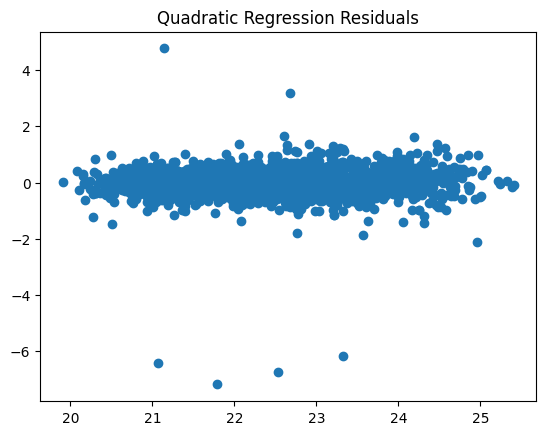

In [ ]:
plt.scatter(prediction,(y_test - prediction))
plt.title("Quadratic Regression Residuals")
plt.savefig("images/Quadratic Regression Residuals.png")
plt.show()


In [606]:
import joblib
joblib.dump(model,"quad_reg.joblib")
joblib.dump(linreg_model,"lin_reg.joblib")
joblib.dump(ridge_reg_quad,"ridge_reg.joblib")
joblib.dump(lasso_reg_quad,"lasso_reg.joblib")

['lasso_reg.joblib']